# Preventing Overfitting with L1 and L2 Regularization

## Objective and Modeling Context

Predict apartment listing prices in Capital Federal using covered area, latitude, longitude, and neighborhood. This stage extends the size-based model in Notebook 2 with location features and examines how Ridge and Lasso regularization affect prediction error and coefficient sparsity.

Models use the same 80/20 split policy (`random_state=42`). RMSE measures prediction error in USD. Run this notebook with the repository root as the working directory.

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from category_encoders import OneHotEncoder
from sklearn.linear_model import Ridge, Lasso
from sklearn.metrics import root_mean_squared_error
from sklearn.model_selection import train_test_split, GridSearchCV, KFold
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from src.wrangle import clean_files

## Data Preparation

The shared cleaning function merges the five CSV files, keeps Capital Federal apartments priced below USD 400,000, retains covered areas between the 10th and 90th percentiles, extracts coordinates and neighborhood, and removes incomplete rows and unused columns. The percentile bounds nominally retain the middle 80% before subsequent cleaning.

The target is `price_aprox_usd`. Price-derived columns are excluded from the predictors.

In [2]:
df = clean_files("data/buenos-aires-real-estate-*.csv")
target_col = "price_aprox_usd"
feature_cols = [col for col in df.columns if col != target_col]
X = df[feature_cols]
y = df[target_col]
X_train_3, X_test_3, y_train_3, y_test_3 = train_test_split(
    X, y, test_size=0.2, random_state=42
)
print("Cleaned data:", df.shape)
print("Predictors:", feature_cols)
print("Training predictors/target:", X_train_3.shape, y_train_3.shape)
print("Test predictors/target:", X_test_3.shape, y_test_3.shape)

Cleaned data: (6247, 5)
Predictors: ['surface_covered_in_m2', 'lat', 'lon', 'neighborhood']
Training predictors/target: (4997, 4) (4997,)
Test predictors/target: (1250, 4) (1250,)


## Ridge and Lasso Regression

Each pipeline one-hot encodes neighborhood, standardizes the encoded predictors, and fits a regularized linear model. Training-derived categories and scaling statistics are applied to test observations.

Ridge uses an L2 coefficient penalty; Lasso uses an L1 penalty and can set coefficients exactly to zero. The fixed settings are Ridge `alpha=1` and Lasso `alpha=100`. Lasso uses `max_iter=100000`, which resolved the alpha-sweep convergence warning without changing its objective or tolerance.

In [3]:
model_ridge_3 = make_pipeline(
    OneHotEncoder(use_cat_names=True),
    StandardScaler(),
    Ridge(alpha=1.0)
)

# Fit model
model_ridge_3.fit(X_train_3, y_train_3)

# Predict on training data
y_pred_ridge_train = model_ridge_3.predict(X_train_3)
rmse_ridge_train = root_mean_squared_error(y_train_3, y_pred_ridge_train)

# Predict on test data
y_pred_ridge_test = model_ridge_3.predict(X_test_3)
rmse_ridge_test = root_mean_squared_error(y_test_3, y_pred_ridge_test)

print(f"Ridge Training RMSE: ${rmse_ridge_train:,.2f}")
print(f"Ridge Test RMSE: ${rmse_ridge_test:,.2f}")
model_lasso_3 = make_pipeline(
    OneHotEncoder(use_cat_names=True),
    StandardScaler(),
    Lasso(alpha=100, max_iter=100000)
)

model_lasso_3.fit(X_train_3, y_train_3)

# Calculate test RMSE
y_pred_lasso_test = model_lasso_3.predict(X_test_3)
rmse_lasso_test = root_mean_squared_error(y_test_3, y_pred_lasso_test)

print(f"Lasso Test RMSE: ${rmse_lasso_test:,.2f}")

Ridge Training RMSE: $34,200.44
Ridge Test RMSE: $33,087.85


Lasso Test RMSE: $33,053.24


## Effect of Regularization Strength

The alpha sweeps show training and test RMSE over the supplied grids. Test curves are diagnostic; hyperparameter selection below uses training-set cross-validation.

For very strong regularization, predictions approach the training-target mean. The Ridge plot therefore uses the actual RMSE of that constant prediction on each split as its limiting reference, rather than labeling target standard deviations as exact limits.

In [4]:
# Test a wide range of alphas across 9 orders of magnitude
alphas = [0.001, 0.01, 0.1, 1, 10, 100, 1000, 10000, 100000, 1000000]
ridge_results = []

for a in alphas:
    # Create and fit pipeline
    model = make_pipeline(
        OneHotEncoder(use_cat_names=True),
        StandardScaler(),
        Ridge(alpha=a)
    )
    model.fit(X_train_3, y_train_3)

    # Calculate RMSE for training and test
    rmse_train = root_mean_squared_error(y_train_3, model.predict(X_train_3))
    rmse_test = root_mean_squared_error(y_test_3, model.predict(X_test_3))

    ridge_results.append({
        "alpha": a,
        "rmse_train": rmse_train,
        "rmse_test": rmse_test
    })

df_ridge_results = pd.DataFrame(ridge_results)
print(df_ridge_results)
lasso_results = []
alphas_lasso = [0.1, 1, 10, 100, 1000]

for a in alphas_lasso:
    model = make_pipeline(
        OneHotEncoder(use_cat_names=True),
        StandardScaler(),
        Lasso(alpha=a, max_iter=100000)
    )
    model.fit(X_train_3, y_train_3)

    rmse_train = root_mean_squared_error(y_train_3, model.predict(X_train_3))
    rmse_test = root_mean_squared_error(y_test_3, model.predict(X_test_3))
    non_zero_features = (model.named_steps["lasso"].coef_ != 0).sum()

    lasso_results.append({
        "alpha": a,
        "rmse_train": rmse_train,
        "rmse_test": rmse_test,
        "non_zero_features": non_zero_features
    })

df_lasso_results = pd.DataFrame(lasso_results)
print(df_lasso_results)

         alpha    rmse_train     rmse_test
0        0.001  34200.432952  33088.372087
1        0.010  34200.432953  33088.367313
2        0.100  34200.432974  33088.319603
3        1.000  34200.435086  33087.845694
4       10.000  34200.639955  33083.415038
5      100.000  34216.977947  33062.388861
6     1000.000  35069.439956  33744.376028
7    10000.000  46235.626251  44495.846605
8   100000.000  57461.877687  55406.360980
9  1000000.000  59460.655403  57344.013143


    alpha    rmse_train     rmse_test  non_zero_features
0     0.1  34200.432978  33088.303772                 58
1     1.0  34200.435537  33087.686878                 58
2    10.0  34200.691205  33081.797922                 58
3   100.0  34224.825010  33053.242280                 56
4  1000.0  34772.392675  33646.034886                 27


Constant training RMSE: $59,700.25
Constant test RMSE: $57,576.13


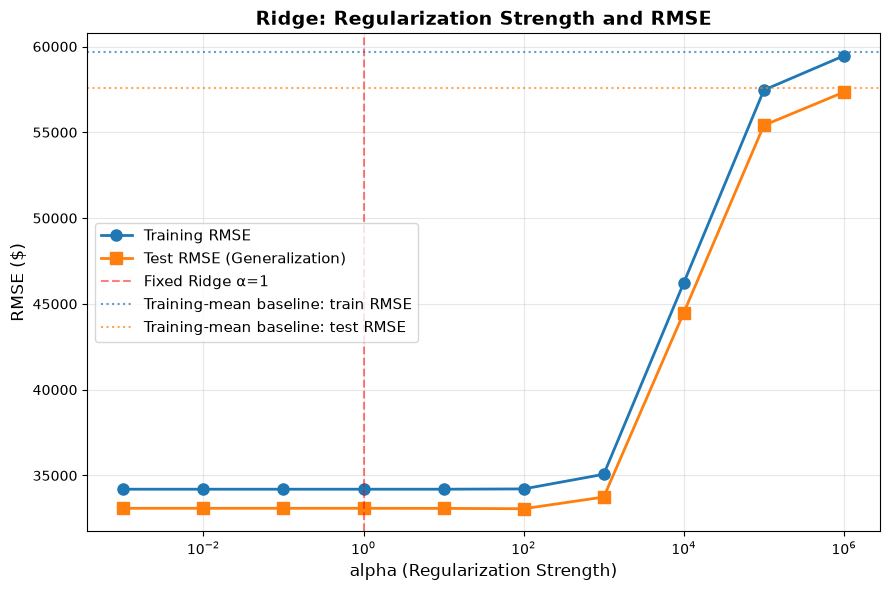

In [5]:
fig, ax = plt.subplots(figsize=(9, 6))
ax.plot(df_ridge_results["alpha"], df_ridge_results["rmse_train"],
        marker='o', linewidth=2, markersize=8, label="Training RMSE")
ax.plot(df_ridge_results["alpha"], df_ridge_results["rmse_test"],
        marker='s', linewidth=2, markersize=8, label="Test RMSE (Generalization)")
ax.axvline(x=1, color='red', linestyle='--', alpha=0.5, label="Fixed Ridge α=1")

# Constant predictions approach the training-target mean
training_mean = y_train_3.mean()
constant_rmse_train = root_mean_squared_error(y_train_3, np.full(len(y_train_3), training_mean))
constant_rmse_test = root_mean_squared_error(y_test_3, np.full(len(y_test_3), training_mean))
print(f"Constant training RMSE: ${constant_rmse_train:,.2f}")
print(f"Constant test RMSE: ${constant_rmse_test:,.2f}")
ax.axhline(constant_rmse_train, color='C0', linestyle=':', alpha=0.7, label="Training-mean baseline: train RMSE")
ax.axhline(constant_rmse_test, color='C1', linestyle=':', alpha=0.7, label="Training-mean baseline: test RMSE")
ax.set_xlabel("alpha (Regularization Strength)", fontsize=12)
ax.set_ylabel("RMSE ($)", fontsize=12)
ax.set_xscale("log")
ax.set_title("Ridge: Regularization Strength and RMSE", fontsize=14, fontweight='bold')
ax.legend(fontsize=11)
ax.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

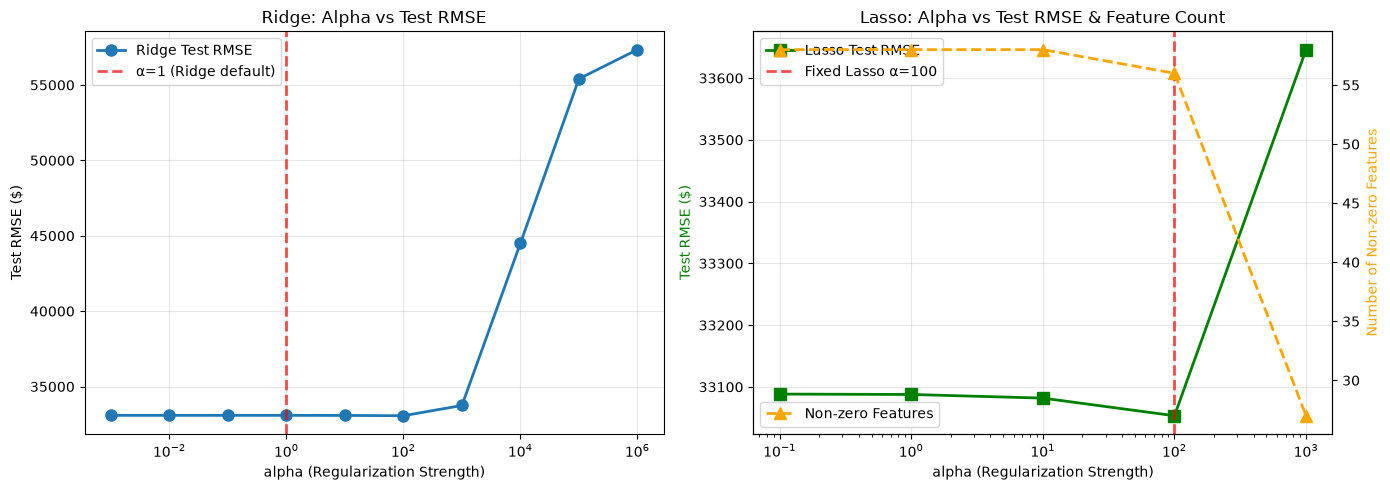

In [6]:
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 5))

# Ridge comparison
ax1.plot(df_ridge_results["alpha"], df_ridge_results["rmse_test"],
         marker='o', linewidth=2, markersize=8, label="Ridge Test RMSE")
ax1.axvline(x=1, color='red', linestyle='--', alpha=0.7, linewidth=2, label="α=1 (Ridge default)")
ax1.set_xlabel("alpha (Regularization Strength)")
ax1.set_ylabel("Test RMSE ($)")
ax1.set_xscale("log")
ax1.set_title("Ridge: Alpha vs Test RMSE")
ax1.legend()
ax1.grid(True, alpha=0.3)

# Lasso comparison with feature count
ax2_twin = ax2.twinx()
ax2.plot(df_lasso_results["alpha"], df_lasso_results["rmse_test"],
         marker='s', linewidth=2, markersize=8, color='green', label="Lasso Test RMSE")
ax2_twin.plot(df_lasso_results["alpha"], df_lasso_results["non_zero_features"],
              marker='^', linewidth=2, markersize=8, color='orange', linestyle='--', label="Non-zero Features")
ax2.axvline(x=100, color='red', linestyle='--', alpha=0.7, linewidth=2, label="Fixed Lasso α=100")
ax2.set_xlabel("alpha (Regularization Strength)")
ax2.set_ylabel("Test RMSE ($)", color='green')
ax2_twin.set_ylabel("Number of Non-zero Features", color='orange')
ax2.set_xscale("log")
ax2.set_title("Lasso: Alpha vs Test RMSE & Feature Count")
ax2.legend(loc='upper left')
ax2_twin.legend(loc='lower left')
ax2.grid(True, alpha=0.3)

plt.tight_layout()
plt.show()

Increasing alpha eventually raises prediction error as the coefficients shrink toward a constant model. A small training/test error gap on this split provides evidence about generalization, but does not prove that overfitting is absent. Lasso's active coefficient count can trend downward with increasing alpha; strict monotonicity is not guaranteed for correlated predictors.

## Cross-Validation and Model Selection

Five unshuffled folds evaluate complete pipelines, so encoding and scaling are learned independently inside every training fold. The Ridge search maximizes mean validation R²; the Lasso search minimizes mean validation MSE. Both preserve the alpha grids above and refit the selected pipeline on the full training split.

The Lasso search uses `max_iter=200000`: a fold fit still warned at 100000 iterations. This adjustment changes the optimization budget, while leaving the penalty, data, and tolerance intact.

In [7]:
from sklearn.model_selection import GridSearchCV, KFold

# Search the complete pipeline so every fold learns its own preprocessing.
cv_folds = KFold(n_splits=5, shuffle=False)
ridge_cv_search = GridSearchCV(
    make_pipeline(OneHotEncoder(use_cat_names=True), StandardScaler(), Ridge()),
    param_grid={"ridge__alpha": alphas},
    scoring="r2", cv=cv_folds, refit=True
)
ridge_cv_search.fit(X_train_3, y_train_3)
ridge_cv_model = ridge_cv_search.best_estimator_
optimal_alpha_ridge = ridge_cv_search.best_params_["ridge__alpha"]
print(f"Ridge selected alpha: {optimal_alpha_ridge}")
print(f"CV Ridge Test RMSE: ${root_mean_squared_error(y_test_3, ridge_cv_model.predict(X_test_3)):,.2f}")

lasso_cv_search = GridSearchCV(
    make_pipeline(OneHotEncoder(use_cat_names=True), StandardScaler(),
                  Lasso(max_iter=200000)),
    param_grid={"lasso__alpha": alphas_lasso},
    scoring="neg_mean_squared_error", cv=cv_folds, refit=True
)
lasso_cv_search.fit(X_train_3, y_train_3)
lasso_cv_model = lasso_cv_search.best_estimator_
optimal_alpha_lasso = lasso_cv_search.best_params_["lasso__alpha"]
print(f"Lasso selected alpha: {optimal_alpha_lasso}")
print(f"CV Lasso Test RMSE: ${root_mean_squared_error(y_test_3, lasso_cv_model.predict(X_test_3)):,.2f}")
print(f"Non-zero features (CV Lasso): {(lasso_cv_model.named_steps['lasso'].coef_ != 0).sum()}")


Ridge selected alpha: 100
CV Ridge Test RMSE: $33,062.39


Lasso selected alpha: 10
CV Lasso Test RMSE: $33,081.80
Non-zero features (CV Lasso): 58


## Coefficient Analysis and Feature Sparsity

Coefficient analysis uses the fixed-alpha Lasso model. Its standardized-model coefficients express USD changes per one training standard deviation of an encoded predictor, conditional on the other inputs. Dividing by the scaler's `scale_` recovers coefficients in original encoded-column units.

All neighborhood indicators are retained; there is no explicitly omitted reference category. Neighborhood contrasts involve differences between raw-unit coefficients, rather than interpreting a standardized coefficient as a dollar premium over an omitted baseline. These are fitted associations, not causal effects.

In [8]:
coefficients = model_lasso_3.named_steps["lasso"].coef_
features = model_lasso_3.named_steps["onehotencoder"].get_feature_names_out()
feat_imp_3 = pd.Series(coefficients, index=features)
raw_unit_coefficients = pd.Series(
    coefficients / model_lasso_3.named_steps["standardscaler"].scale_,
    index=features
)
lasso_zeros_count = int((feat_imp_3 == 0).sum())
sparsity_percentage = lasso_zeros_count / len(feat_imp_3) * 100
print(f"Fixed Lasso: {lasso_zeros_count} zero coefficients out of {len(feat_imp_3)} ({sparsity_percentage:.1f}%).")
coefficient_table = pd.DataFrame({
    "standardized_coefficient_usd": feat_imp_3,
    "raw_unit_coefficient_usd": raw_unit_coefficients
})
print(coefficient_table.loc[feat_imp_3.abs().nlargest(10).index].to_string())
top_positive = feat_imp_3.nlargest(5)
top_negative = feat_imp_3.nsmallest(5)
print("\nLargest standardized coefficients:\n", top_positive)
print("\nSmallest standardized coefficients:\n", top_negative)

Fixed Lasso: 3 zero coefficients out of 59 (5.1%).
                            standardized_coefficient_usd  raw_unit_coefficient_usd
surface_covered_in_m2                       40288.951342               2225.128655
neighborhood_Palermo                        10307.789054              34020.037422
neighborhood_Puerto Madero                  10259.328813             118097.157936
lat                                          9774.243999             362452.082874
neighborhood_Belgrano                        7279.832231              25850.004384
neighborhood_Recoleta                        5572.862250              38855.256834
lon                                          4915.613898             127172.027701
neighborhood_Las Cañitas                     4648.428347              70211.395883
neighborhood_Barrio Norte                    4581.230456              27384.517729
neighborhood_Balvanera                      -4560.405995             -25014.969349

Largest standardized coefficients:


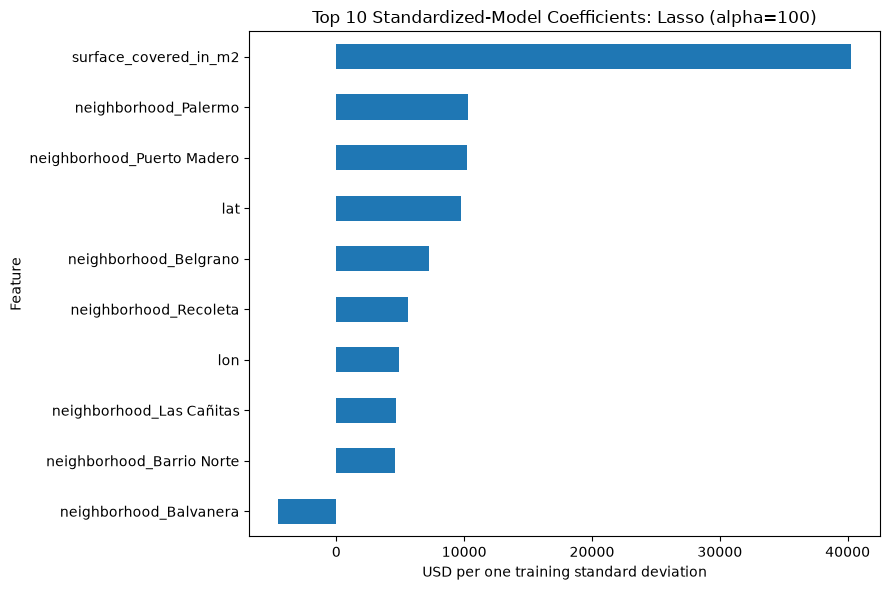

In [9]:
fig, ax = plt.subplots(figsize=(9, 6))
feat_imp_3.sort_values(key=abs).tail(10).plot(kind="barh", ax=ax)
ax.set_title("Top 10 Standardized-Model Coefficients: Lasso (alpha=100)")
ax.set_xlabel("USD per one training standard deviation")
ax.set_ylabel("Feature")
plt.tight_layout()
plt.show()

The measured zero count describes sparsity at this alpha, not proof that excluded predictors are noise. The fitted model retains most encoded coefficients; a claim of dramatic feature compression is unsupported here.

## Residual Analysis

Inspect test residuals for the fixed-alpha Lasso model against predicted price. Curvature or changing spread can indicate limitations of the linear model. Broadly random scatter is useful diagnostic evidence but does not establish that all systematic structure has been captured.

This notebook analyzes the multivariate model's residuals; it does not reconstruct the prior size-only model or claim a direct residual comparison.

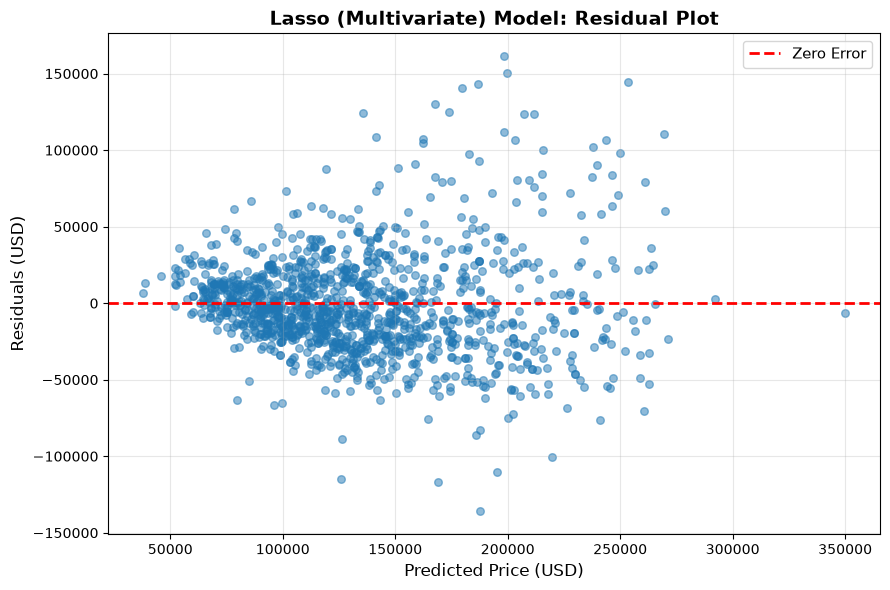

Mean of residuals: $-1,449.38
Std of residuals: $33,034.67
Min residual: $-135,828.79
Max residual: $161,606.27


In [10]:
# Get residuals from Lasso predictions on test set
y_pred_lasso = model_lasso_3.predict(X_test_3)
residuals_lasso = y_test_3 - y_pred_lasso

# Create residual plot
fig, ax = plt.subplots(figsize=(9, 6))
ax.scatter(y_pred_lasso, residuals_lasso, alpha=0.5, s=30)
ax.axhline(y=0, color='r', linestyle='--', linewidth=2, label='Zero Error')
ax.set_xlabel("Predicted Price (USD)", fontsize=12)
ax.set_ylabel("Residuals (USD)", fontsize=12)
ax.set_title("Lasso (Multivariate) Model: Residual Plot", fontsize=14, fontweight='bold')
ax.legend(fontsize=11)
ax.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

# Summary statistics
print(f"Mean of residuals: ${residuals_lasso.mean():,.2f}")
print(f"Std of residuals: ${residuals_lasso.std():,.2f}")
print(f"Min residual: ${residuals_lasso.min():,.2f}")
print(f"Max residual: ${residuals_lasso.max():,.2f}")

## Model Comparison

The table summarizes the fixed-alpha models. Cross-validation results above describe separately selected models; their selection scores differ, so alpha values are interpreted within each model family.

In [11]:
ridge_metrics = {
    "Model": "Ridge (α=1.0)",
    "RMSE_train": rmse_ridge_train,
    "RMSE_test": rmse_ridge_test,
    "Non-zero_features": int((model_ridge_3.named_steps["ridge"].coef_ != 0).sum())
}

lasso_metrics = {
    "Model": "Lasso (α=100)",
    "RMSE_train": root_mean_squared_error(y_train_3, model_lasso_3.predict(X_train_3)),
    "RMSE_test": rmse_lasso_test,
    "Non-zero_features": (feat_imp_3 != 0).sum()
}

df_comparison = pd.DataFrame([ridge_metrics, lasso_metrics])
print(df_comparison)

           Model    RMSE_train     RMSE_test  Non-zero_features
0  Ridge (α=1.0)  34200.435086  33087.845694                 59
1  Lasso (α=100)  34224.825010  33053.242280                 56


## Findings and Limitations

The computed results show similar test RMSE for the regularized models. Stronger penalties eventually reduce predictive accuracy, while the fixed-alpha Lasso model produces modest coefficient sparsity. Coefficient magnitudes depend on scaling and the jointly fitted predictors.

These findings describe one random split of a filtered listing dataset. A favorable train/test comparison and a large sample-to-feature ratio do not prove absence of overfitting. Repeated test-set inspection limits its role as an independent final benchmark. Cleaning uses dataset-wide covered-area percentiles before the split; fold-safe model preprocessing does not remove that upstream selection limitation. The price cap, area filtering, and complete-case selection restrict applicability to the retained market segment. Linear effects may leave nonlinear relationships and unequal residual variance unresolved.